# BÀI THỰC HÀNH CHAPTER 12: DEPLOYING MACHINE LEARNING MODELS
### Môn học: Phát Triển Hệ Thống Thông Minh (Intelligent System Development)
**Giáo trình:** *Python Machine Learning - Wei-Meng Lee (Chapter 12)*  
**Tập dữ liệu:** *Pima Indians Diabetes Database* (`diabet.csv` / `diabetes.csv`)

---
### 🎯 Mục tiêu thực hành:
1. **Khám phá và Tiền xử lý dữ liệu y tế:** Phát hiện và xử lý các giá trị 0 phi lý (Glucose, Huyết áp, BMI = 0) bằng phương pháp gán `NaN` và điền giá trị trung bình (`mean`).
2. **Phân tích tương quan & Trích chọn đặc trưng:** Sử dụng ma trận hệ số tương quan Pearson và Heatmap để lựa chọn Top 3 đặc trưng ảnh hưởng mạnh nhất: `Glucose`, `BMI`, `Age`.
3. **Đánh giá & So sánh mô hình bằng 10-Fold Cross-Validation:** So sánh 4 thuật toán (*Logistic Regression, KNN, SVM Linear, SVM RBF*).
4. **Khảo sát mở rộng:** Đo lường hiệu năng của 4 mô hình trên 4 tập đặc trưng khác nhau (Top 3, Top 5, Top 7, All 8 đặc trưng) và chứng minh hiện tượng *Lời nguyền chiều dữ liệu (Curse of Dimensionality)* trên KNN.
5. **Huấn luyện mô hình tối ưu & Đóng gói (Model Persistence):** Huấn luyện KNN ($k=19$) và lưu file `diabetes.sav` bằng `pickle`.
6. **Triển khai Web Service REST API & Client:** Tích hợp với Flask REST API và giao diện Web tương tác.

## 1. Nạp và Khám phá Dữ liệu (Load & Inspect Data)
- Tập dữ liệu gồm 768 mẫu bệnh nhân nữ người da đỏ Pima từ 21 tuổi trở lên.
- Biến mục tiêu `Outcome`: `0` (Không mắc tiểu đường) và `1` (Mắc tiểu đường).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings('ignore')

# Nạp dữ liệu từ file CSV
try:
    df = pd.read_csv('diabet.csv')
    print("--> Nạp thành công file 'diabet.csv'")
except FileNotFoundError:
    df = pd.read_csv('diabetes.csv')
    print("--> Nạp thành công file 'diabetes.csv'")

print("Kích thước tập dữ liệu:", df.shape)
df.info()
display(df.head(10))

--> Nạp thành công file 'diabet.csv'
Kích thước tập dữ liệu: (768, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


## 2. Tiền xử lý Dữ liệu khuyết thiếu (Data Cleaning & Imputation)
> **Lý giải y học:** Các chỉ số sinh tồn như `Glucose` (đường huyết), `BloodPressure` (huyết áp), `SkinThickness` (độ dày nếp gấp da), `BMI` (chỉ số khối cơ thể) **không thể bằng 0 ở người còn sống**.
> Các số 0 này thực chất là giá trị bị thiếu (Missing values). Ta phải thay thế bằng `NaN` và điền bù bằng giá trị trung bình (`mean`) của từng cột.

In [2]:
# Kiểm tra số lượng giá trị null và số lượng giá trị 0 ở từng cột
print("--- Số lượng giá trị Null ban đầu ---")
print(df.isnull().sum())

print("\n--- Số lượng giá trị bằng 0 ở từng cột ---")
print(df.eq(0).sum())

--- Số lượng giá trị Null ban đầu ---
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

--- Số lượng giá trị bằng 0 ở từng cột ---
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [3]:
# Thay thế các giá trị 0 phi lý bằng NaN và điền bù bằng giá trị trung bình (mean)
cols_to_clean = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
df[cols_to_clean] = df[cols_to_clean].replace(0, np.nan)
df.fillna(df.mean(), inplace=True)

print("--- Số lượng giá trị 0 sau khi xử lý (Cột Outcome giữ nguyên 0/1 làm nhãn) ---")
print(df.eq(0).sum())

--- Số lượng giá trị 0 sau khi xử lý (Cột Outcome giữ nguyên 0/1 làm nhãn) ---
Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


## 3. Phân tích Tương quan & Lựa chọn Đặc trưng (Correlation Analysis & Feature Selection)
- Hệ số tương quan Pearson đo lường mức độ liên kết tuyến tính giữa từng đặc trưng với biến nhãn `Outcome`.
- Các đặc trưng có tương quan cao nhất thể hiện khả năng phân biệt bệnh nhân mắc tiểu đường tốt nhất.

In [4]:
# Tính toán ma trận hệ số tương quan Pearson
corr = df.corr()
display(corr)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.127911,0.208522,0.082989,0.056027,0.021565,-0.033523,0.544341,0.221898
Glucose,0.127911,1.000000,0.218367,0.192991,0.420157,0.230941,0.137060,0.266534,0.492928
BloodPressure,0.208522,0.218367,1.000000,0.192816,0.072517,0.281268,-0.002763,0.324595,0.166074
SkinThickness,0.082989,0.192991,0.192816,1.000000,0.158139,0.542398,0.100966,0.127872,0.215299
Insulin,0.056027,0.420157,0.072517,0.158139,1.000000,0.166586,0.098634,0.136734,0.214411
BMI,0.021565,0.230941,0.281268,0.542398,0.166586,1.000000,0.153400,0.025519,0.311924
DiabetesPedigreeFunction,-0.033523,0.137060,-0.002763,0.100966,0.098634,0.153400,1.000000,0.033561,0.173844
Age,0.544341,0.266534,0.324595,0.127872,0.136734,0.025519,0.033561,1.000000,0.238356
Outcome,0.221898,0.492928,0.166074,0.215299,0.214411,0.311924,0.173844,0.238356,1.000000


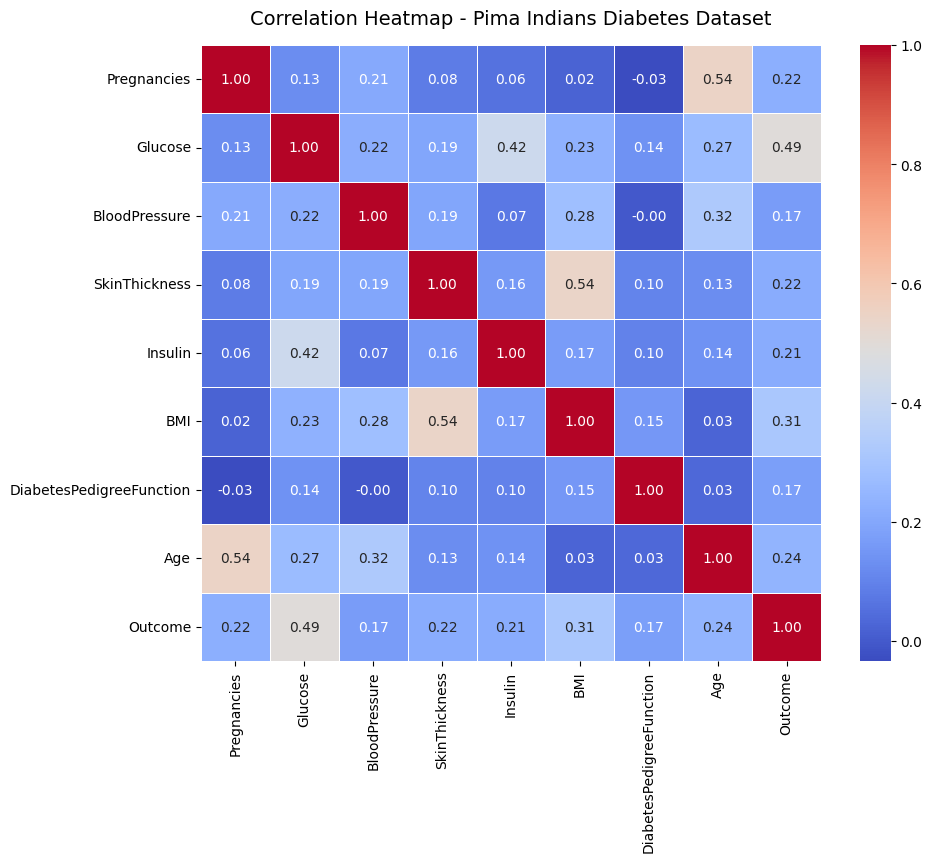

In [5]:
# Trực quan hóa ma trận tương quan bằng biểu đồ Heatmap (Seaborn & Matplotlib)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar=True)
plt.title("Correlation Heatmap - Pima Indians Diabetes Dataset", fontsize=14, pad=15)
plt.show()

In [6]:
# Sắp xếp và trích xuất danh sách đặc trưng có tương quan cao nhất với Outcome
top_corr_features = df.corr()['Outcome'].abs().sort_values(ascending=False)
print("--- Mức độ tương quan với nhãn Outcome (Sắp xếp giảm dần) ---")
for feat, val in top_corr_features.items():
    print(f"- {feat:<25}: {val:.4f}")

print("\n=> 3 đặc trưng hàng đầu được chọn theo Chapter 12: ['Glucose', 'BMI', 'Age']")

--- Mức độ tương quan với nhãn Outcome (Sắp xếp giảm dần) ---
- Outcome                  : 1.0000
- Glucose                  : 0.4929
- BMI                      : 0.3119
- Age                      : 0.2384
- Pregnancies              : 0.2219
- SkinThickness            : 0.2153
- Insulin                  : 0.2144
- DiabetesPedigreeFunction : 0.1738
- BloodPressure            : 0.1661

=> 3 đặc trưng hàng đầu được chọn theo Chapter 12: ['Glucose', 'BMI', 'Age']


## 4. Đánh giá và So sánh các Thuật toán Học máy (Model Evaluation with 10-Fold Cross-Validation)
> **Tại sao dùng 10-Fold Cross-Validation?**  
> Tập dữ liệu nhỏ (768 mẫu). 10-Fold CV chia tập dữ liệu thành 10 phần: mỗi lượt dùng 9 phần để train và 1 phần để test. Kết quả là trung bình của 10 lần đo, giúp loại bỏ yếu tố may rủi khi phân chia tập dữ liệu và đánh giá khách quan khả năng tổng quát hóa của mô hình.

In [7]:
from sklearn import linear_model, svm
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# Tách biến đầu vào X (Top 3 đặc trưng) và biến mục tiêu y (Outcome)
X_top3 = df[['Glucose', 'BMI', 'Age']]
y = df.iloc[:, 8]

results_list = []

# 1. Logistic Regression
log_reg = linear_model.LogisticRegression()
log_reg_score = cross_val_score(log_reg, X_top3, y, cv=10, scoring='accuracy').mean()
results_list.append({"Algorithm": "Logistic Regression", "Accuracy": log_reg_score})
print(f"1. Logistic Regression Score : {log_reg_score*100:.2f}%")

# 2. K-Nearest Neighbors (Quét tìm k tối ưu từ 1 đến 50)
ks = list(range(1, 51, 2))
cv_scores = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X_top3, y, cv=10, scoring='accuracy').mean()
    cv_scores.append(score)

best_knn_score = max(cv_scores)
best_k = ks[cv_scores.index(best_knn_score)]
results_list.append({"Algorithm": f"K-Nearest Neighbors (k={best_k})", "Accuracy": best_knn_score})
print(f"2. K-Nearest Neighbors (k={best_k}) : {best_knn_score*100:.2f}%")

# 3. SVM Linear Kernel
svm_linear = svm.SVC(kernel='linear')
svm_lin_score = cross_val_score(svm_linear, X_top3, y, cv=10, scoring='accuracy').mean()
results_list.append({"Algorithm": "SVM (Linear Kernel)", "Accuracy": svm_lin_score})
print(f"3. SVM Linear Kernel Score   : {svm_lin_score*100:.2f}%")

# 4. SVM RBF Kernel
svm_rbf = svm.SVC(kernel='rbf')
svm_rbf_score = cross_val_score(svm_rbf, X_top3, y, cv=10, scoring='accuracy').mean()
results_list.append({"Algorithm": "SVM (RBF Kernel)", "Accuracy": svm_rbf_score})
print(f"4. SVM RBF Kernel Score      : {svm_rbf_score*100:.2f}%")

1. Logistic Regression Score : 76.70%


2. K-Nearest Neighbors (k=19) : 77.21%


3. SVM Linear Kernel Score   : 76.57%
4. SVM RBF Kernel Score      : 76.57%


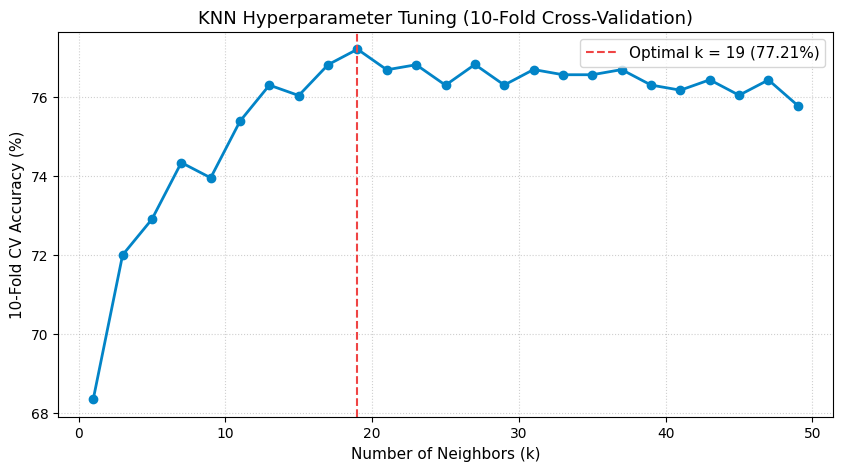

In [8]:
# Biểu đồ trực quan hóa quá trình tìm kiếm k tối ưu cho thuật toán KNN
plt.figure(figsize=(10, 5))
plt.plot(ks, [s * 100 for s in cv_scores], marker='o', color='#0284c7', linewidth=2, markersize=6)
plt.axvline(best_k, color='#ef4444', linestyle='--', label=f'Optimal k = {best_k} ({best_knn_score*100:.2f}%)')
plt.title('KNN Hyperparameter Tuning (10-Fold Cross-Validation)', fontsize=13)
plt.xlabel('Number of Neighbors (k)', fontsize=11)
plt.ylabel('10-Fold CV Accuracy (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

In [9]:
# Bảng xếp hạng độ chính xác của 4 thuật toán trên Top 3 đặc trưng
df_results = pd.DataFrame(results_list)
df_results['Accuracy (%)'] = df_results['Accuracy'].apply(lambda x: f"{x*100:.2f}%")
display(df_results.sort_values(by='Accuracy', ascending=False)[['Algorithm', 'Accuracy (%)']])

,Algorithm,Accuracy (%)
1,K-Nearest Neighbors (k=19),77.21%
0,Logistic Regression,76.70%
3,SVM (RBF Kernel),76.57%
2,SVM (Linear Kernel),76.57%


## 5. Thực nghiệm Mở rộng: Đối chiếu Hiệu năng trên các Tập Đặc trưng (3, 5, 7, 8 Features)
> **Nhận xét chuyên sâu:**  
> - Đối với **KNN**, độ chính xác cao nhất đạt được ở **Top 3 đặc trưng (77.21%)** và giảm dần khi đưa vào 5, 7 và 8 đặc trưng. Điều này minh chứng cho hiện tượng **Lời nguyền chiều dữ liệu (*Curse of Dimensionality*)**: trong không gian nhiều chiều, khoảng cách Euclidean bị bão hòa và các đặc trưng thứ yếu làm tăng độ nhiễu.
> - Mô hình **KNN ($k=19$) với Top 3 đặc trưng** là giải pháp tối ưu nhất cả về độ chính xác và tính thực tiễn khi triển khai Web API.

In [10]:
sorted_feat_list = df.corr()['Outcome'].abs().sort_values(ascending=False).index[1:].tolist()

feature_subsets = {
    "Top 3 Features": sorted_feat_list[:3],
    "Top 5 Features": sorted_feat_list[:5],
    "Top 7 Features": sorted_feat_list[:7],
    "All 8 Features": sorted_feat_list
}

benchmark_rows = []
for subset_name, feats in feature_subsets.items():
    X_sub = df[feats]
    
    # Logistic Regression
    lr_acc = cross_val_score(linear_model.LogisticRegression(max_iter=1000), X_sub, y, cv=10, scoring='accuracy').mean()
    
    # KNN scan
    knn_scores_sub = [cross_val_score(KNeighborsClassifier(n_neighbors=k_val), X_sub, y, cv=10, scoring='accuracy').mean() for k_val in range(1, 36, 2)]
    best_knn_sub = max(knn_scores_sub)
    best_k_sub = list(range(1, 36, 2))[knn_scores_sub.index(best_knn_sub)]
    
    # SVMs
    svm_lin_acc = cross_val_score(svm.SVC(kernel='linear'), X_sub, y, cv=10, scoring='accuracy').mean()
    svm_rbf_acc = cross_val_score(svm.SVC(kernel='rbf'), X_sub, y, cv=10, scoring='accuracy').mean()
    
    benchmark_rows.append({
        "Tập đặc trưng": subset_name,
        "Danh sách đặc trưng": ", ".join(feats),
        "Logistic Regression": f"{lr_acc*100:.2f}%",
        "KNN (Tối ưu)": f"{best_knn_sub*100:.2f}% (k={best_k_sub})",
        "SVM Linear": f"{svm_lin_acc*100:.2f}%",
        "SVM RBF": f"{svm_rbf_acc*100:.2f}%"
    })

df_benchmark = pd.DataFrame(benchmark_rows)
display(df_benchmark)

,Tập đặc trưng,Danh sách đặc trưng,Logistic Regression,KNN (Tối ưu),SVM Linear,SVM RBF
0,Top 3 Features,"Glucose, BMI, Age",76.70%,77.21% (k=19),76.57%,76.57%
1,Top 5 Features,"Glucose, BMI, Age, Pregnancies, SkinThickness",76.83%,77.10% (k=21),76.83%,76.57%
2,Top 7 Features,"Glucose, BMI, Age, Pregnancies, SkinThickness,...",77.21%,75.66% (k=35),76.43%,75.66%
3,All 8 Features,"Glucose, BMI, Age, Pregnancies, SkinThickness,...",76.70%,74.23% (k=31),76.30%,75.79%


## 6. Huấn luyện Mô hình Tối ưu & Đóng gói (Model Training & Persistence)
- Huấn luyện thuật toán **KNN ($k=19$)** trên toàn bộ 768 mẫu dữ liệu với 3 đặc trưng: `Glucose`, `BMI`, `Age`.
- Đóng gói mô hình thành tệp nhị phân `diabetes.sav` bằng `pickle` để Web Service có thể nạp nhanh chóng mà không cần huấn luyện lại.

In [11]:
# Huấn luyện mô hình tối ưu KNN (k=19) trên Top 3 đặc trưng
model = KNeighborsClassifier(n_neighbors=19)
model.fit(X_top3, y)

# Lưu mô hình ra tệp nhị phân diabetes.sav
filename = 'diabetes.sav'
pickle.dump(model, open(filename, 'wb'))
print(f"--> Đã huấn luyện và lưu mô hình thành công vào '{filename}'")

--> Đã huấn luyện và lưu mô hình thành công vào 'diabetes.sav'


In [12]:
# Kiểm thử nạp lại file .sav và dự đoán 2 mẫu bệnh nhân điển hình
loaded_model = pickle.load(open(filename, 'rb'))

# Mẫu 1: Người bình thường (Glucose=100, BMI=30, Age=29)
patient1 = pd.DataFrame([[100, 30, 29]], columns=['Glucose', 'BMI', 'Age'])
pred1 = loaded_model.predict(patient1)[0]
conf1 = np.amax(loaded_model.predict_proba(patient1)[0]) * 100
print(f"Bệnh nhân 1 (Glucose=100, BMI=30, Age=29) -> Kết quả: {'Diabetic (Tiểu đường)' if pred1==1 else 'Not Diabetic (Bình thường)'} | Độ tin cậy: {conf1:.2f}%")

# Mẫu 2: Người nguy cơ cao (Glucose=160, BMI=42, Age=50)
patient2 = pd.DataFrame([[160, 42, 50]], columns=['Glucose', 'BMI', 'Age'])
pred2 = loaded_model.predict(patient2)[0]
conf2 = np.amax(loaded_model.predict_proba(patient2)[0]) * 100
print(f"Bệnh nhân 2 (Glucose=160, BMI=42, Age=50) -> Kết quả: {'Diabetic (Tiểu đường)' if pred2==1 else 'Not Diabetic (Bình thường)'} | Độ tin cậy: {conf2:.2f}%")

Bệnh nhân 1 (Glucose=100, BMI=30, Age=29) -> Kết quả: Not Diabetic (Bình thường) | Độ tin cậy: 78.95%
Bệnh nhân 2 (Glucose=160, BMI=42, Age=50) -> Kết quả: Diabetic (Tiểu đường) | Độ tin cậy: 84.21%


## 7. Triển khai REST API Web Service & Client Script
- Xuất file `REST_API.py` (Flask micro-service tiếp nhận POST request JSON) và `Predict_Diabetes.py` (Client kiểm thử).

In [ ]:
%%writefile REST_API.py
import pickle
import numpy as np
import pandas as pd
from flask import Flask, request, jsonify
from flask_cors import CORS

app = Flask(__name__)
CORS(app)

filename = "diabetes.sav"
loaded_model = pickle.load(open(filename, "rb"))

@app.route('/diabetes/v1/predict', methods=['POST'])
def predict():
    features = request.json
    try:
        glucose = float(features.get("Glucose", 0))
        bmi = float(features.get("BMI", 0))
        age = float(features.get("Age", 0))
        
        input_df = pd.DataFrame([[glucose, bmi, age]], columns=['Glucose', 'BMI', 'Age'])
        prediction = loaded_model.predict(input_df)
        confidence = loaded_model.predict_proba(input_df)
        
        response = {
            "prediction": int(prediction[0]),
            "label": "Diabetic" if int(prediction[0]) == 1 else "Not Diabetic",
            "confidence": str(round(np.amax(confidence[0]) * 100, 2)),
            "risk_level": "Cao" if int(prediction[0]) == 1 else "Thấp"
        }
        return jsonify(response)
    except Exception as e:
        return jsonify({"error": str(e)}), 400

if __name__ == '__main__':
    print("Starting Diabetes Prediction REST API on http://127.0.0.1:5000/ ...")
    app.run(host='0.0.0.0', port=5000, debug=False)


Overwriting REST_API.py


In [14]:
%%writefile Predict_Diabetes.py
import json
import requests

def predict_diabetes(Glucose, BMI, Age):
    url = "http://127.0.0.1:5000/diabetes/v1/predict"
    data = {
        "Glucose": float(Glucose),
        "BMI": float(BMI), 
        "Age": float(Age)
    }
    headers = {"Content-type": "application/json"}
    response = requests.post(url, data=json.dumps(data), headers=headers)
    return response.json()

if __name__ == '__main__':
    print("=== CHƯƠNG TRÌNH KIỂM THỬ DỰ ĐOÁN TIỂU ĐƯỜNG CLIENT ===")
    Glucose = input('Nhập Glucose (mg/dL) [mặc định 100]: ') or '100'
    BMI = input('Nhập BMI [mặc định 30]: ') or '30'
    Age = input('Nhập Age (tuổi) [mặc định 29]: ') or '29'
    
    try:
        result = predict_diabetes(Glucose, BMI, Age)
        print("\n--- KẾT QUẢ TỪ REST API ---")
        print("Chẩn đoán:", result.get('label'))
        print("Phân lớp (Class 0/1):", result.get('prediction'))
        print("Độ tin cậy:", str(result.get('confidence')) + '%')
        print("Mức độ nguy cơ:", result.get('risk_level'))
    except Exception as e:
        print("Lỗi kết nối tới Server API:", e)


Overwriting Predict_Diabetes.py


In [15]:
# Kiểm thử trực tiếp hàm dự đoán client ngay trong Notebook
test_cases = {
    "Bệnh nhân 1 (Bình thường)": [100, 28.5, 29],
    "Bệnh nhân 2 (Nguy cơ cao)": [165, 38.0, 52]
}

print("=== KIỂM THỬ DỰ ĐOÁN TRỰC TIẾP TRONG NOTEBOOK ===")
for name, values in test_cases.items():
    sample_df = pd.DataFrame([values], columns=['Glucose', 'BMI', 'Age'])
    p = loaded_model.predict(sample_df)[0]
    c = np.amax(loaded_model.predict_proba(sample_df)[0]) * 100
    label = "Diabetic (Tiểu đường)" if p == 1 else "Not Diabetic (Bình thường)"
    print(f"* {name}: {label} | Độ tin cậy: {c:.2f}%")


=== KIỂM THỬ DỰ ĐOÁN TRỰC TIẾP TRONG NOTEBOOK ===
* Bệnh nhân 1 (Bình thường): Not Diabetic (Bình thường) | Độ tin cậy: 84.21%
* Bệnh nhân 2 (Nguy cơ cao): Diabetic (Tiểu đường) | Độ tin cậy: 84.21%
